# 🤖 Unsupervised Learning & Clustering

## Learn by Doing

Today you will learn:
- What is unsupervised learning?
- What is clustering?
- How K-Means clustering works
- How machines group similar data

💡 No labels required!

# 🧠 Supervised vs Unsupervised Learning

## Supervised Learning
- Data has labels
- Example:
    - Pass / Fail
    - Spam / Not Spam

## Unsupervised Learning
- Data has NO labels
- Machine finds hidden patterns

Example:
- Customer groups
- Similar products
- Friend suggestions

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans

In [ ]:
# Simple student dataset

data = {
    "Hours_Studied": [1,2,3,4,5,6,7,8,2,7],
    "Attendance":    [40,45,50,55,65,70,80,90,35,85]
}

df = pd.DataFrame(data)

df

,Hours_Studied,Attendance
0,1,40
1,2,45
2,3,50
3,4,55
4,5,65
5,6,70
6,7,80
7,8,90
8,2,35
9,7,85


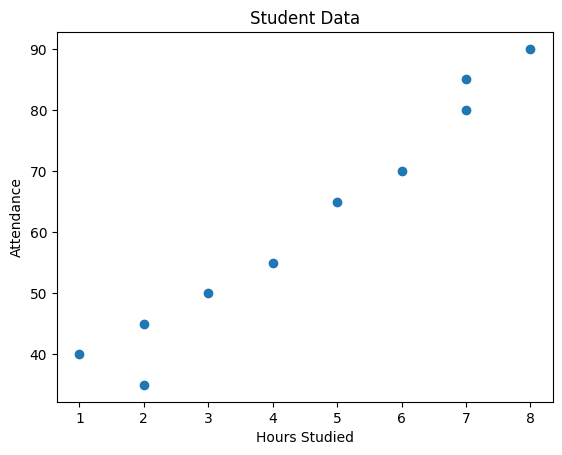

In [ ]:
plt.scatter(df["Hours_Studied"], df["Attendance"])

plt.xlabel("Hours Studied")
plt.ylabel("Attendance")

plt.title("Student Data")

plt.show()

# 🎯 Clustering

Clustering means:
👉 Grouping similar data points together.

Goal:
- Similar points → same cluster
- Different points → different clusters

Example:
- Hardworking students
- Average students
- Low-engagement students

In [ ]:
# Create K-Means model

kmeans = KMeans(n_clusters=2, random_state=42)

# Train model
kmeans.fit(df)

KMeans(n_clusters=2, random_state=42)

In [ ]:
# Cluster assignments

kmeans.labels_

array([0, 0, 0, 0, 1, 1, 1, 1, 0, 1], dtype=int32)

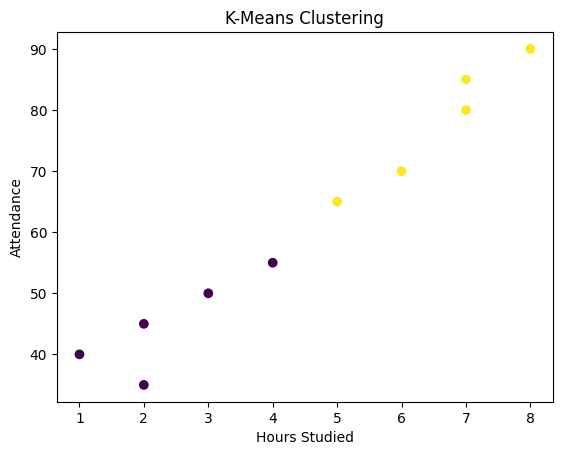

In [ ]:
plt.scatter(
    df["Hours_Studied"],
    df["Attendance"],
    c=kmeans.labels_
)

plt.xlabel("Hours Studied")
plt.ylabel("Attendance")

plt.title("K-Means Clustering")

plt.show()

In [ ]:
kmeans.cluster_centers_

array([[ 2.4, 45. ],
       [ 6.6, 78. ]])

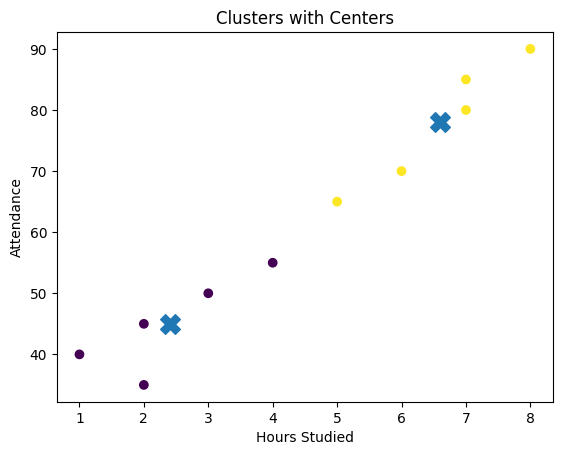

In [ ]:
plt.scatter(
    df["Hours_Studied"],
    df["Attendance"],
    c=kmeans.labels_
)

plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    s=200,
    marker='X'
)

plt.xlabel("Hours Studied")
plt.ylabel("Attendance")

plt.title("Clusters with Centers")

plt.show()

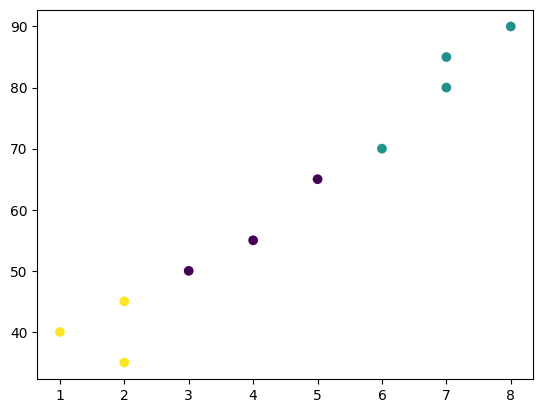

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42)

kmeans.fit(df)

plt.scatter(
    df["Hours_Studied"],
    df["Attendance"],
    c=kmeans.labels_
)

plt.show()

# 🌍 Real-World Applications of Clustering

- Customer segmentation
- Friend recommendations
- Product grouping
- Fraud detection

# 🧪 Mini Activity

Try:
1. Change number of clusters
2. Add new students
3. Observe cluster changes

💡 Experiment like a real ML engineer!

# ✅ What You Learned

- Unsupervised learning uses unlabeled data
- Clustering groups similar data
- K-Means is a clustering algorithm
- Machines can discover hidden patterns

👏 You now know all 3 major ML types:
- Regression
- Classification
- Clustering

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib import rc

# Display animations in Colab
rc('animation', html='jshtml')

# --------------------------------------------------
# Generate sample data
# --------------------------------------------------

np.random.seed(42)

cluster1 = np.random.randn(100, 2) + [4, 4]
cluster2 = np.random.randn(100, 2) + [6, 5]

X = np.vstack([cluster1, cluster2])

# --------------------------------------------------
# Initial random centroids
# --------------------------------------------------

centroids = np.array([
    [1, 8],
    [8, 2]
])


# Store animation history
history_centroids = []
history_labels = []
history_titles = []

# Initial state (before clustering)
history_centroids.append(centroids.copy())
history_labels.append(None)
history_titles.append("Initial Random Centroids")

# --------------------------------------------------
# K-Means iterations
# --------------------------------------------------

for iteration in range(5):

    # Step 1: Assign points to nearest centroid
    distances = []

    # Calculate distance from every point to every centroid
    for point in X:

        point_distances = []

        for centroid in centroids:

            distance = np.linalg.norm(point - centroid)

            point_distances.append(distance)

        distances.append(point_distances)

    distances = np.array(distances)


    labels = np.argmin(distances, axis=1)

    history_centroids.append(centroids.copy())
    history_labels.append(labels.copy())
    history_titles.append(
        f"Iteration {iteration + 1}: Assign Points"
    )

    # Step 2: Move centroids
    new_centroids = np.array([
        X[labels == i].mean(axis=0)
        for i in range(len(centroids))
    ])

    history_centroids.append(new_centroids.copy())
    history_labels.append(labels.copy())
    history_titles.append(
        f"Iteration {iteration + 1}: Move Centroids"
    )

    centroids = new_centroids

# --------------------------------------------------
# Animation
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(6, 6))

def update(frame):

    ax.clear()

    labels = history_labels[frame]
    centers = history_centroids[frame]

    # Initial frame
    if labels is None:
        ax.scatter(
            X[:, 0],
            X[:, 1],
            color='gray',
            s=60
        )
    else:
        ax.scatter(
            X[:, 0],
            X[:, 1],
            c=labels,
            s=60
        )

    ax.scatter(
        centers[:, 0],
        centers[:, 1],
        marker='X',
        s=300,
        c='red'
    )

    ax.set_xlim(0, 11)
    ax.set_ylim(0, 11)

    ax.set_title(history_titles[frame])

ani = FuncAnimation(
    fig,
    update,
    frames=len(history_centroids),
    interval=1500,
    repeat=False
)

# Prevent static figure from appearing
plt.close(fig)

ani

In [ ]:
ani.save(
    "kmeans_animation.gif",
    writer="pillow",
    fps=1
)

# 🔍 Beyond K-Means

K-Means is popular, but not the only clustering algorithm.

Two other important methods are:

1. DBSCAN
2. Hierarchical Clustering

# 🌌 DBSCAN Clustering

DBSCAN groups:
👉 Dense nearby points together

It can:
✅ Find irregular cluster shapes
✅ Detect outliers/noise

Unlike K-Means:
❌ No need to specify number of clusters

In [ ]:
from sklearn.cluster import DBSCAN

In [ ]:
df = pd.DataFrame({
    "Hours_Studied": [
        2,3,2,3,4,          # Cluster 1
        10,11,10,12,11,     # Cluster 2
        18                  # Noise
    ],

    "Attendance": [
        60,62,58,61,63,
        85,87,84,88,86,
        40
    ]
})

print(df)

    Hours_Studied  Attendance
0               2          60
1               3          62
2               2          58
3               3          61
4               4          63
5              10          85
6              11          87
7              10          84
8              12          88
9              11          86
10             18          40


In [ ]:
X = df[["Hours_Studied", "Attendance"]]

dbscan = DBSCAN(
    eps=4,
    min_samples=2
)

labels = dbscan.fit_predict(X)

print(labels)

[ 0  0  0  0  0  1  1  1  1  1 -1]


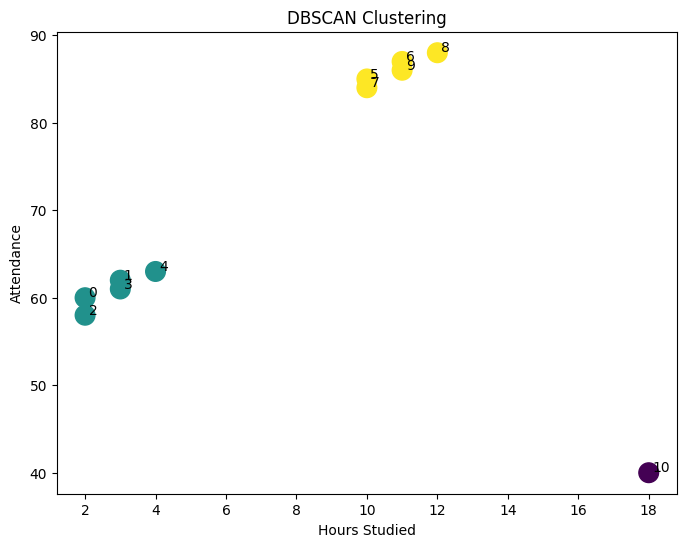

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    df["Hours_Studied"],
    df["Attendance"],
    c=labels,
    s=200
)

for i,row in df.iterrows():
    plt.text(
        row["Hours_Studied"]+0.1,
        row["Attendance"]+0.1,
        str(i)
    )

plt.xlabel("Hours Studied")
plt.ylabel("Attendance")

plt.title("DBSCAN Clustering")

plt.show()

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Circle

fig, ax = plt.subplots(figsize=(8,6))

eps = 4

def update(frame):

    ax.clear()

    ax.scatter(
        df["Hours_Studied"],
        df["Attendance"],
        s=120
    )

    point = X.iloc[frame]

    circle = Circle(
        (point["Hours_Studied"],
         point["Attendance"]),
        eps,
        fill=False,
        linewidth=2
    )

    ax.add_patch(circle)

    ax.scatter(
        point["Hours_Studied"],
        point["Attendance"],
        s=300
    )

    ax.set_title(
        f"Checking Point {frame}"
    )

ani = FuncAnimation(
    fig,
    update,
    frames=len(df),
    interval=1200
)

# Prevent static figure from appearing
plt.close(fig)

ani

# 🧠 K-Means vs DBSCAN

## K-Means
- Needs number of clusters

## DBSCAN
- Finds dense regions
- Can detect noise/outliers
- Handles irregular shapes